# HOUSING WORKBOOK - MACHINE LEARNING

### DATASET LINK  

*https://www.kaggle.com/datasets/vallabhadattap/kingcountyhousing*

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## 1. Get and understand the data

In [3]:
df = pd.read_csv("KC_housing_data.csv")
print(df.shape)
print(df.head)

(4600, 18)
<bound method NDFrame.head of                      date         price  bedrooms  bathrooms  sqft_living  \
0     2014-05-02 00:00:00  3.130000e+05       3.0       1.50         1340   
1     2014-05-02 00:00:00  2.384000e+06       5.0       2.50         3650   
2     2014-05-02 00:00:00  3.420000e+05       3.0       2.00         1930   
3     2014-05-02 00:00:00  4.200000e+05       3.0       2.25         2000   
4     2014-05-02 00:00:00  5.500000e+05       4.0       2.50         1940   
...                   ...           ...       ...        ...          ...   
4595  2014-07-09 00:00:00  3.081667e+05       3.0       1.75         1510   
4596  2014-07-09 00:00:00  5.343333e+05       3.0       2.50         1460   
4597  2014-07-09 00:00:00  4.169042e+05       3.0       2.50         3010   
4598  2014-07-10 00:00:00  2.034000e+05       4.0       2.00         2090   
4599  2014-07-10 00:00:00  2.206000e+05       3.0       2.50         1490   

      sqft_lot  floors  waterfront

## 2. Explore and clean

In [4]:
missing = df.isna().sum() # missing values in the dataset check
missing

date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64

In [5]:
df["street"].describe()

count                      4600
unique                     4525
top       2520 Mulberry Walk NE
freq                          4
Name: street, dtype: object

In [6]:
dups = df[df["street"].duplicated(keep=False)].sort_values(["street", "date"]) # duplicate houses on the dataset were houses that were sold multiple times
dups[["street", "date", "price", "sqft_living", "bedrooms"]].head(20)

,street,date,price,sqft_living,bedrooms
3956,1018 NE 96th St,2014-07-03 00:00:00,425000.0,1400,3.0
4280,1018 NE 96th St,2014-07-09 00:00:00,440000.0,1270,3.0
475,106 24th Ave E,2014-05-12 00:00:00,490000.0,1230,2.0
2671,106 24th Ave E,2014-06-17 00:00:00,479000.0,1230,2.0
2239,11034 NE 26th Pl,2014-06-10 00:00:00,895000.0,2550,5.0
2418,11034 NE 26th Pl,2014-06-12 00:00:00,1034500.0,2370,4.0
4429,1149-1199 91st Ave NE,2014-05-28 00:00:00,532500.0,2050,2.0
2761,1149-1199 91st Ave NE,2014-06-18 00:00:00,4489000.0,6430,4.0
1325,11716 16th Ave NE,2014-05-27 00:00:00,312000.0,1255,3.0
2602,11716 16th Ave NE,2014-06-16 00:00:00,340000.0,1212,3.0


In [7]:
print("duplicate rows :" , df.duplicated().sum())

duplicate rows : 0


In [8]:
df = df[df["price"] > 0] # no NaNs but some values can still be 0 which would skew the result

In [9]:
(df["price"] == 0).sum()

np.int64(0)

## 3. Choosing X and Y variables

In [10]:
features = ["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors", "condition"]
price = "price"

X = df[features]
Y = df[price]

## 4. Check initial regression assumptions

There are two main assumpions made about the data to check for initial regression.

### Linearity
We assume linearity in that as the x variable features increase, the y variable of price should also increase. For example, if the number of bedrooms offered in the house increases, its value naturally should increase.

### No multicollinearity
There were multiple different columns in this dataset that might have been correlated with each other in a way that would disrupt the model and destabilise the coefficients (the coefficients are essentially multipliers that measure the impact of one variable to another). An example of this are the multiple different square feet measurements of each floor. Conflicting columns are removed.

## 5. Split into training & test data

In [11]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, random_state = 50)

## 6. Create and train the model

In [12]:
model = LinearRegression()    # The negative bedrooms coefficient looks wrong but has a standard explanation. It’s the effect of adding a bedroom while holding sqft_living fixed. If total floor area doesn’t change, an extra bedroom means smaller rooms, which buyers value less. Bedrooms and living area are strongly correlated, so the model splits their effect in a way that looks odd. This is multicollinearity.
model.fit(X_train, Y_train)

print("Intercept:", model.intercept_)
pd.Series(model.coef_, index=features).sort_values()

Intercept: -145455.26126634132


bedrooms      -61056.938268
sqft_lot          -0.681709
sqft_living      301.103641
bathrooms      14652.922942
floors         16634.237848
condition      61653.594787
dtype: float64

## 7. Make predictions

In [13]:
Y_pred = model.predict(X_test)
pd.DataFrame({"actual": Y_test, "predicted": Y_pred})

,actual,predicted
49,838000.000000,832519.485671
2223,429000.000000,377566.145779
1983,499950.000000,631157.286810
4367,292285.714286,581556.146962
3287,352000.000000,281193.109366
...,...,...
1807,253000.000000,446913.586577
3104,396500.000000,613375.726181
582,717000.000000,286749.069636
783,437500.000000,599677.010823


Text(0.5, 1.0, 'Actual vs predicted house prices')

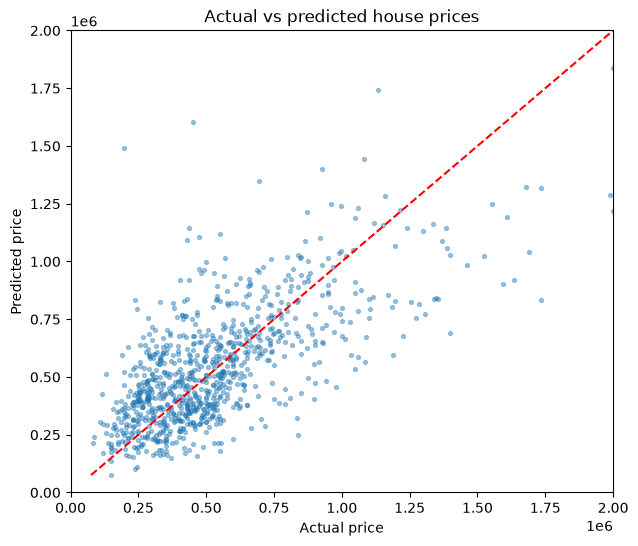

In [14]:
plt.figure(figsize=(7,6))
plt.scatter(Y_test, Y_pred, s=8, alpha = 0.4)


lims = [min(Y_test.min(), Y_pred.min()), max(Y_test.max(), Y_pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction") # line of best fit
plt.xlim(0, 2_000_000)
plt.ylim(0, 2_000_000)
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Actual vs predicted house prices")

In [15]:
check = X_test.copy()
check["actual"] = Y_test
check["predicted"] = Y_pred
check["error"] = check["actual"] - check["predicted"]
check = check.join(df[["city", "statezip"]])
check.sort_values("error", ascending=False).head(10)

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,actual,predicted,error,city,statezip
4350,3.0,2.00,1180,7793,1.0,4,26590000.0,3.139181e+05,2.627608e+07,Kent,WA 98031
4346,3.0,2.50,2190,11394,1.0,3,12899000.0,5.612508e+05,1.233775e+07,Seattle,WA 98199
1637,4.0,3.50,5550,28078,2.0,4,3710000.0,1.593469e+06,2.116531e+06,Medina,WA 98039
2654,5.0,6.75,9640,13068,1.0,3,4668000.0,2.743493e+06,1.924507e+06,Mercer Island,WA 98040
4347,4.0,1.00,2100,9200,1.0,3,2110000.0,4.526109e+05,1.657389e+06,Tukwila,WA 98168
404,3.0,2.25,3000,11665,1.5,3,2400000.0,8.096139e+05,1.590386e+06,Sammamish,WA 98075
2772,4.0,4.25,4850,12445,2.0,5,3000000.0,1.465997e+06,1.534003e+06,Kirkland,WA 98034
4261,5.0,3.00,4290,20445,2.0,4,2680000.0,1.150899e+06,1.529101e+06,Medina,WA 98039
252,7.0,4.50,6210,8856,2.5,5,3200000.0,1.706754e+06,1.493246e+06,Seattle,WA 98109
745,4.0,1.75,3550,19865,2.0,3,2100000.0,9.095646e+05,1.190435e+06,Medina,WA 98039


## 8. Evaluate model performance

The model was succesful, and the line of best fit matched x = y practically perfectly, showing that the model learned the linearity patterns from the features vs the price. The main issue was that with less data on the higher value properties, the model clearly undervalues the prices of the costlier homes, and by a substantial amount. This may have been handled by the model due to it wanting to reduce error and not throw out higher end predictions but instead move them closer to the average value.

In [18]:
mae = mean_absolute_error(Y_test, Y_pred)
rmse = np.sqrt(mean_squared_error(Y_test, Y_pred))
r2 = r2_score(Y_test, Y_pred)

print(mae)
print(rmse)
print(r2)

222295.27222447554
1000863.0320927157
0.06259351937340796


## 9. Analyse residuals and check remaining assumptions

In [ ]:
residuals = Y_test - Y_pred
plt.scatter(Y_pred, residuals, s=6, alpha=0.4)
plt.axhline(0, color="r", linestyle="--")
plt.xlabel("Predicted price"); plt.ylabel("Residual"); plt.show()

In [ ]:
from scipy import stats
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(residuals, bins=50); ax[0].set_title("Residual distribution")
stats.probplot(residuals, plot=ax[1]); ax[1].set_title("Q-Q plot")
plt.show()

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for a, col in zip(ax.ravel(), features):
    a.scatter(X_test[col], residuals, s=5, alpha=0.3)
    a.axhline(0, color="r"); a.set_title(col)
plt.show()

In [ ]:
plt.hist(Y_test, bins=50, range=(0, 2_000_000), alpha=0.5, label="actual")
plt.hist(Y_pred, bins=50, range=(0, 2_000_000), alpha=0.5, label="predicted")
plt.legend();
plt.title("Variation in Actual vs Predicted price");
plt.xlabel("Price"); 
plt.show() 

The residuals seem to be a healthy and manageable amount. As for the remaining assumptions:

### Autocorrelation
The residuals should be independent from house to house, but in theory the economy or trends of the market might have affected all homes during this short period of data.

### Homoscedasticity
The variance of the residuals are not constant across all levels of the predictions. The more expensive the home, the higher the error in prediction vs actual value, which would be something to analyse further, potentially by adding more higher value property data could the model be made to be better.
